# APIs públicas · Tiempo y datos abiertos

Datos meteorológicos, económicos, de calendario y sísmicos de APIs públicas sin clave, analizados con `pandas` y dibujados con Matplotlib: [Open-Meteo](https://open-meteo.com) (tiempo actual, previsión e histórico), el [Banco Mundial](https://datahelpdesk.worldbank.org/knowledgebase/articles/889392) (indicadores por país), [Frankfurter](https://frankfurter.dev) (tipos de cambio del BCE), [Nager.Date](https://date.nager.at) (festivos), el [catálogo sísmico del EMSC](https://www.seismicportal.eu/fdsn-wsevent.html) y la posición de la Estación Espacial Internacional ([wheretheiss.at](https://wheretheiss.at)).

Necesita conexión a internet. Siempre que se puede se piden periodos cerrados del pasado, cuyos datos ya no cambian; el tiempo actual, la previsión y la posición de la ISS son instantáneas del momento de la ejecución.

## 1. El tiempo ahora en las siete islas

Pedir a Open-Meteo en una sola petición (listas de latitudes y longitudes separadas por comas) la temperatura, el viento y el código de tiempo actuales de las siete capitales insulares. Traducir el código WMO a una descripción y mostrar una tabla ordenada de más a menos calor.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import requests

sesion = requests.Session()
sesion.headers["User-Agent"] = "ejercicios-python/1.0"


def obtener_json(url, **params):
    respuesta = sesion.get(url, params=params, timeout=60)
    respuesta.raise_for_status()
    return respuesta.json()


MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]

CAPITALES = {
    "Santa Cruz de Tenerife": (28.4636, -16.2518), "Las Palmas de Gran Canaria": (28.1235, -15.4363),
    "Arrecife": (28.9630, -13.5477), "Puerto del Rosario": (28.5004, -13.8627),
    "Santa Cruz de La Palma": (28.6835, -17.7642), "San Sebastián de La Gomera": (28.0916, -17.1133),
    "Valverde": (27.8064, -17.9158),
}
TIEMPO_WMO = {0: "despejado", 1: "casi despejado", 2: "parcialmente nuboso", 3: "cubierto", 45: "niebla", 48: "niebla",
              51: "llovizna débil", 53: "llovizna", 55: "llovizna intensa", 61: "lluvia débil", 63: "lluvia", 65: "lluvia fuerte",
              80: "chubascos débiles", 81: "chubascos", 82: "chubascos fuertes", 95: "tormenta"}

lugares = obtener_json(
    "https://api.open-meteo.com/v1/forecast",
    latitude=",".join(str(la) for la, _ in CAPITALES.values()),
    longitude=",".join(str(lo) for _, lo in CAPITALES.values()),
    current="temperature_2m,wind_speed_10m,weather_code",
    timezone="Atlantic/Canary",
)
ahora = pd.DataFrame(
    [{"capital": nombre, "temperatura (°C)": l["current"]["temperature_2m"], "viento (km/h)": l["current"]["wind_speed_10m"],
      "tiempo": TIEMPO_WMO.get(l["current"]["weather_code"], f"código {l['current']['weather_code']}")}
     for nombre, l in zip(CAPITALES, lugares)]
).sort_values("temperatura (°C)", ascending=False)
print("Hora local de los datos:", lugares[0]["current"]["time"])
print(ahora.to_string(index=False))
assert len(lugares) == 7 and ahora["temperatura (°C)"].between(-10, 50).all()

Hora local de los datos: 2026-11-22T19:30
                   capital  temperatura (°C)  viento (km/h)              tiempo
    Santa Cruz de Tenerife              22.3            4.9            cubierto
San Sebastián de La Gomera              22.3            6.4           despejado
                  Arrecife              21.8           15.0      casi despejado
Las Palmas de Gran Canaria              21.7            3.8 parcialmente nuboso
        Puerto del Rosario              21.5           17.4      casi despejado
    Santa Cruz de La Palma              20.8            8.6            cubierto
                  Valverde              17.1            6.9              niebla


## 2. Previsión de siete días

Pedir la previsión diaria de Las Palmas de Gran Canaria (máxima, mínima y precipitación de los próximos 7 días), convertirla en un `DataFrame` con las fechas como índice y dibujar la banda entre mínima y máxima con la lluvia en barras sobre un segundo eje.

            máxima  mínima  lluvia (mm)
time                                   
2026-11-22    23.9    18.8          0.0
2026-11-23    24.1    19.0          0.0
2026-11-24    23.7    20.2          0.0
2026-11-25    23.2    20.2          2.9
2026-11-26    21.5    18.7          0.8
2026-11-27    21.3    18.1          0.6
2026-11-28    22.4    17.1          0.0


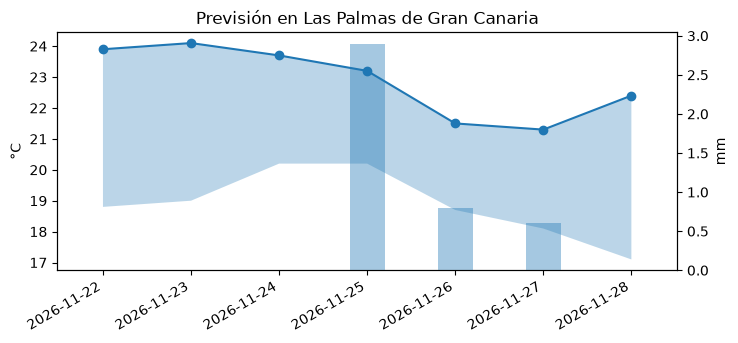

In [2]:
prevision = obtener_json(
    "https://api.open-meteo.com/v1/forecast",
    latitude=28.1235, longitude=-15.4363, timezone="Atlantic/Canary", forecast_days=7,
    daily="temperature_2m_max,temperature_2m_min,precipitation_sum",
)
dias = pd.DataFrame(prevision["daily"]).set_index("time")
dias.index = pd.to_datetime(dias.index)
dias.columns = ["máxima", "mínima", "lluvia (mm)"]
print(dias)
assert len(dias) == 7 and (dias["máxima"] >= dias["mínima"]).all()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.fill_between(dias.index, dias["mínima"], dias["máxima"], alpha=0.3, label="mínima–máxima")
ax.plot(dias.index, dias["máxima"], marker="o")
ax.set_ylabel("°C")
ax2 = ax.twinx()
ax2.bar(dias.index, dias["lluvia (mm)"], width=0.4, alpha=0.4, color="tab:blue")
ax2.set_ylabel("mm")
ax.set_title("Previsión en Las Palmas de Gran Canaria")
fig.autofmt_xdate()
plt.show()

## 3. Un año de temperaturas

Con la API de histórico de Open-Meteo, descargar la temperatura máxima diaria de 2025 en Santa Cruz de Tenerife. Calcular la media mensual con `resample`, el día más caluroso y cuántos días se superaron los 30 °C, y dibujar las medias mensuales en barras.

365 días | día más caluroso: 16-07-2025 (36.9 °C) | días > 30 °C: 15


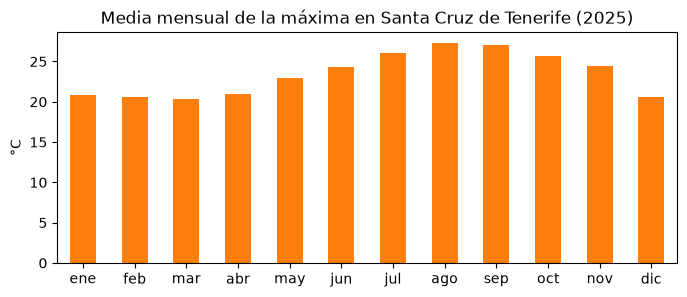

In [3]:
historico = obtener_json(
    "https://archive-api.open-meteo.com/v1/archive",
    latitude=28.4636, longitude=-16.2518, timezone="Atlantic/Canary",
    start_date="2025-01-01", end_date="2025-12-31", daily="temperature_2m_max",
)
maximas = pd.Series(historico["daily"]["temperature_2m_max"], index=pd.to_datetime(historico["daily"]["time"]), name="máxima")
mensual = maximas.resample("MS").mean().round(1)
print(f"{len(maximas)} días | día más caluroso: {maximas.idxmax():%d-%m-%Y} ({maximas.max()} °C) | días > 30 °C: {(maximas > 30).sum()}")
assert len(maximas) == 365 and len(mensual) == 12

mensual.index = [MESES[m - 1] for m in mensual.index.month]
mensual.plot.bar(figsize=(8, 3), color="tab:orange", rot=0, title="Media mensual de la máxima en Santa Cruz de Tenerife (2025)")
plt.ylabel("°C")
plt.show()

## 4. Indicadores del Banco Mundial

Consultar en la API del Banco Mundial la ficha de España (región, nivel de renta y capital) y la población total (`SP.POP.TOTL`) de España, Portugal, Francia e Italia entre 2000 y 2023 en una sola petición. Pasar los datos a una tabla con un país por columna y calcular el crecimiento de cada país en el periodo.

In [4]:
_, [espana] = obtener_json("https://api.worldbank.org/v2/country/ESP", format="json")
print(espana["name"], "|", espana["region"]["value"], "|", espana["incomeLevel"]["value"], "| capital:", espana["capitalCity"])

meta, filas = obtener_json(
    "https://api.worldbank.org/v2/country/ESP;PRT;FRA;ITA/indicator/SP.POP.TOTL",
    format="json", date="2000:2023", per_page=200,
)
poblacion = (
    pd.DataFrame([{"pais": f["country"]["value"], "año": int(f["date"]), "poblacion": f["value"]} for f in filas])
    .pivot(index="año", columns="pais", values="poblacion")
)
print((poblacion.loc[[2000, 2010, 2023]] / 1e6).round(2), "\n(millones de habitantes)")
crecimiento = (poblacion.loc[2023] / poblacion.loc[2000] - 1) * 100
print(crecimiento.round(1).sort_values(ascending=False).to_string(), "(% de 2000 a 2023)")
assert meta["total"] == 4 * 24 and poblacion.shape == (24, 4)

Spain | Europe & Central Asia | High income | capital: Madrid
pais  France  Italy  Portugal  Spain
año                                 
2000   60.92  56.94     10.29  40.57
2010   65.03  59.82     10.57  46.58
2023   68.37  58.98     10.58  48.35 
(millones de habitantes)
pais
Spain       19.2
France      12.2
Italy        3.6
Portugal     2.8 (% de 2000 a 2023)


## 5. Tipos de cambio

Con Frankfurter (tipos de referencia del Banco Central Europeo) descargar la serie diaria del euro frente al dólar y la libra en 2025. Calcular la media de cada mes, el día de máximo y mínimo del dólar, y convertir una lista de precios en euros al tipo del último día del año.

In [5]:
cambios = obtener_json("https://api.frankfurter.dev/v1/2025-01-01..2025-12-31", base="EUR", symbols="USD,GBP")
serie = pd.DataFrame.from_dict(cambios["rates"], orient="index")
serie.index = pd.to_datetime(serie.index)
serie = serie[serie.index.year == 2025]  # el primer dato puede ser del último día hábil de 2024
print(len(serie), "días hábiles con cotización")
medias = serie.resample("MS").mean().round(4)
medias.index = [MESES[m - 1] for m in medias.index.month]
print(medias.T.to_string())
print(f"Dólar: máximo {serie['USD'].max()} el {serie['USD'].idxmax():%d-%m}, mínimo {serie['USD'].min()} el {serie['USD'].idxmin():%d-%m}")

ultimo = serie.iloc[-1]
precios = {"ferry Las Palmas–Santa Cruz": 52.0, "guagua al aeropuerto": 2.95, "entrada al Teide": 30.0}
for concepto, euros in precios.items():
    print(f"{concepto:<28} {euros:>6.2f} € = {euros * ultimo['USD']:>6.2f} $ = {euros * ultimo['GBP']:>6.2f} £")
assert serie.index.is_monotonic_increasing and serie.index.day_of_week.max() <= 4 and len(medias) == 12

255 días hábiles con cotización
        ene     feb     mar     abr     may     jun     jul     ago     sep     oct    nov     dic
GBP  0.8391  0.8307  0.8370  0.8538  0.8435  0.8498  0.8647  0.8653  0.8689  0.8716  0.880  0.8750
USD  1.0354  1.0412  1.0807  1.1214  1.1278  1.1516  1.1677  1.1631  1.1732  1.1630  1.156  1.1709
Dólar: máximo 1.1837 el 17-09, mínimo 1.0198 el 13-01
ferry Las Palmas–Santa Cruz   52.00 € =  61.10 $ =  45.38 £
guagua al aeropuerto           2.95 € =   3.47 $ =   2.57 £
entrada al Teide              30.00 € =  35.25 $ =  26.18 £


## 6. Festivos

Descargar con Nager.Date los festivos de 2026 en España y separar los nacionales de los de Canarias (región `ES-CN`). Buscar el próximo festivo en Canarias a partir del 22 de noviembre de 2026 y listar los fines de semana largos del año según la propia API.

In [6]:
from datetime import date

festivos = obtener_json("https://date.nager.at/api/v3/PublicHolidays/2026/ES")
nacionales = [f for f in festivos if f["global"]]
canarios = [f for f in festivos if f["global"] or "ES-CN" in (f["counties"] or [])]
print(f"{len(festivos)} festivos en total, {len(nacionales)} nacionales, {len(canarios)} aplicables en Canarias")
for f in canarios:
    print(f"  {f['date']}  {f['localName']}{'' if f['global'] else '  (Canarias)'}")

referencia = date(2026, 11, 22)
proximo = min((f for f in canarios if date.fromisoformat(f["date"]) > referencia), key=lambda f: f["date"])
print("Próximo festivo desde el", referencia, "->", proximo["date"], proximo["localName"])

puentes = obtener_json("https://date.nager.at/api/v3/LongWeekend/2026/ES")
print("Fines de semana largos:", [(p["startDate"][5:], p["dayCount"]) for p in puentes])
assert all(date.fromisoformat(f["date"]).year == 2026 for f in festivos)

32 festivos en total, 10 nacionales, 12 aplicables en Canarias
  2026-01-01  Año Nuevo
  2026-01-06  Día de Reyes / Epifanía del Señor
  2026-04-02  Jueves Santo  (Canarias)
  2026-04-03  Viernes Santo
  2026-05-01  Fiesta del trabajo
  2026-05-30  Día de Canarias  (Canarias)
  2026-08-15  Asunción
  2026-10-12  Fiesta Nacional de España
  2026-11-01  Día de todos los Santos
  2026-12-06  Día de la Constitución
  2026-12-08  Inmaculada Concepción
  2026-12-25  Navidad
Próximo festivo desde el 2026-11-22 -> 2026-12-06 Día de la Constitución
Fines de semana largos: [('01-01', 4), ('01-03', 4), ('04-03', 3), ('05-01', 3), ('10-10', 3), ('12-05', 4), ('12-25', 3)]


## 7. Terremotos durante la erupción de La Palma

La erupción del volcán de Tajogaite empezó el 19 de septiembre de 2021. Pedir al catálogo del EMSC (servicio FDSN en formato GeoJSON) los terremotos de magnitud 3,5 o más en la zona de La Palma entre septiembre y diciembre de 2021. Contarlos por semana, mostrar los cinco más fuertes y dibujar su posición con el tamaño del punto según la magnitud y el color según la profundidad.

425 terremotos de magnitud ≥ 3,5
                  fecha  magnitud  longitud  latitud  profundidad (km)
2021-11-03 07:27:34.800       4.9    -17.82    28.59              40.0
2021-11-19 01:08:45.800       4.9    -17.83    28.59              40.0
2021-10-23 15:34:47.600       4.7    -17.79    28.60              38.0
2021-10-26 16:25:34.800       4.7    -17.77    28.68              40.0
2021-10-26 23:53:14.500       4.7    -17.76    28.66              40.0
Terremotos por semana (la semana termina en la fecha indicada):
fecha
2021-09-19     2
2021-09-26     0
2021-10-03     4
2021-10-10    44
2021-10-17    29
2021-10-24    64
2021-10-31    62
2021-11-07    44
2021-11-14    31
2021-11-21    47
2021-11-28    37
2021-12-05    51
2021-12-12     9
2021-12-19     1
Freq: W-SUN


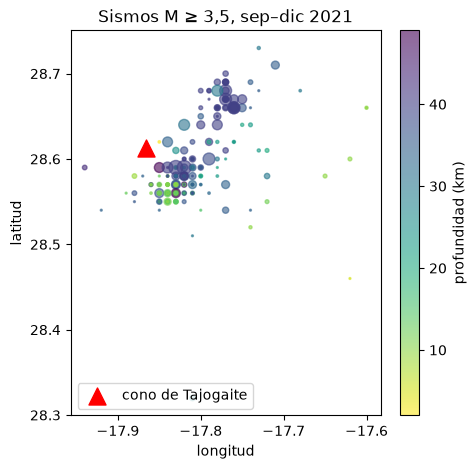

In [7]:
sismos = obtener_json(
    "https://www.seismicportal.eu/fdsnws/event/1/query",
    format="json", starttime="2021-09-01", endtime="2022-01-01", minmagnitude=3.5,
    minlatitude=28.3, maxlatitude=28.9, minlongitude=-18.1, maxlongitude=-17.6, limit=5000,
)
tabla = pd.DataFrame(
    [{"fecha": pd.to_datetime(f["properties"]["time"]).tz_localize(None), "magnitud": f["properties"]["mag"],
      "longitud": f["properties"]["lon"], "latitud": f["properties"]["lat"],
      "profundidad (km)": f["properties"]["depth"]} for f in sismos["features"]]
).sort_values("fecha")
print(len(tabla), "terremotos de magnitud ≥ 3,5")
print(tabla.nlargest(5, "magnitud").to_string(index=False))
por_semana = tabla.set_index("fecha").resample("W")["magnitud"].count()
print("Terremotos por semana (la semana termina en la fecha indicada):")
print(por_semana.to_string())
assert tabla["magnitud"].min() >= 3.5 and tabla["fecha"].min() >= pd.Timestamp("2021-09-01")

fig, ax = plt.subplots(figsize=(5, 5))
puntos = ax.scatter(tabla["longitud"], tabla["latitud"], s=(tabla["magnitud"] - 3) ** 3 * 15, c=tabla["profundidad (km)"], cmap="viridis_r", alpha=0.6)
ax.scatter([-17.866], [28.613], marker="^", s=150, color="red", label="cono de Tajogaite")
fig.colorbar(puntos, label="profundidad (km)")
ax.set(xlabel="longitud", ylabel="latitud", title="Sismos M ≥ 3,5, sep–dic 2021")
ax.legend(loc="lower left")
plt.show()

## 8. ¿Dónde está la Estación Espacial?

Pedir la posición actual de la ISS (satélite 25544) y calcular con la fórmula del semiverseno a qué distancia horizontal está de Las Palmas de Gran Canaria. Mostrar también su altitud y velocidad.

In [8]:
import math


def distancia_km(lat1, lon1, lat2, lon2):
    la1, lo1, la2, lo2 = map(math.radians, (lat1, lon1, lat2, lon2))
    h = math.sin((la2 - la1) / 2) ** 2 + math.cos(la1) * math.cos(la2) * math.sin((lo2 - lo1) / 2) ** 2
    return 2 * 6371 * math.asin(math.sqrt(h))


iss = obtener_json("https://api.wheretheiss.at/v1/satellites/25544")
lejos = distancia_km(iss["latitude"], iss["longitude"], *CAPITALES["Las Palmas de Gran Canaria"])
print(f"Posición: {iss['latitude']:.2f}°, {iss['longitude']:.2f}° | altitud {iss['altitude']:.0f} km | velocidad {iss['velocity']:.0f} km/h")
print(f"Distancia a Las Palmas sobre la superficie: {lejos:.0f} km")
assert -52 <= iss["latitude"] <= 52 and 0 <= lejos <= math.pi * 6371

Posición: -3.86°, -123.42° | altitud 417 km | velocidad 27588 km/h
Distancia a Las Palmas sobre la superficie: 11971 km
